In [2]:
import os
import re
import json
import time
import random
import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix)

from sklearn.utils import resample

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import (Input,Embedding,LSTM, Dense,Dropout)

from tensorflow.keras.callbacks import (EarlyStopping,ModelCheckpoint)

warnings.filterwarnings("ignore")

print("All libraries imported successfully!")
print("TensorFlow Version:", tf.__version__)

All libraries imported successfully!
TensorFlow Version: 2.21.0


In [3]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

os.makedirs("models", exist_ok=True)
os.makedirs("artifacts", exist_ok=True)

print("Random seed configured successfully!")

Random seed configured successfully!


In [4]:
df = pd.read_csv("C:/Users/mchar/Final Project/Bitext_Customer_Support_Dataset.csv")

print("Dataset Loaded Successfully!")

Dataset Loaded Successfully!


In [5]:
print("Dataset Shape:", df.shape)

display(df.head())

Dataset Shape: (26872, 5)


,flags,instruction,category,intent,response
0,B,question about cancelling order {{Order Number}},ORDER,cancel_order,I've understood you have a question regarding ...
1,BQZ,i have a question about cancelling oorder {{Or...,ORDER,cancel_order,I've been informed that you have a question ab...
2,BLQZ,i need help cancelling puchase {{Order Number}},ORDER,cancel_order,I can sense that you're seeking assistance wit...
3,BL,I need to cancel purchase {{Order Number}},ORDER,cancel_order,I understood that you need assistance with can...
4,BCELN,"I cannot afford this order, cancel purchase {{...",ORDER,cancel_order,I'm sensitive to the fact that you're facing f...


In [6]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26872 entries, 0 to 26871
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   flags        26872 non-null  object
 1   instruction  26872 non-null  object
 2   category     26872 non-null  object
 3   intent       26872 non-null  object
 4   response     26872 non-null  object
dtypes: object(5)
memory usage: 1.0+ MB
None


In [9]:
print(df.isnull().sum())

flags          0
instruction    0
category       0
intent         0
response       0
dtype: int64


In [7]:
print(df.duplicated().sum())

0


In [8]:
print(df.columns.tolist())

['flags', 'instruction', 'category', 'intent', 'response']


In [9]:
df = df.dropna(subset=['instruction', 'category', 'intent', 'response'])

df = df.reset_index(drop=True)

print("Dataset Shape:", df.shape)
print("Missing Values:")
print(df.isnull().sum())

Dataset Shape: (26872, 5)
Missing Values:
flags          0
instruction    0
category       0
intent         0
response       0
dtype: int64


In [10]:
#textcontractions
contractions = {
    "can't": "cannot",
    "won't": "will not",
    "don't": "do not",
    "doesn't": "does not",
    "didn't": "did not",
    "isn't": "is not",
    "aren't": "are not",
    "wasn't": "was not",
    "weren't": "were not",
    "i'm": "i am",
    "you're": "you are",
    "we're": "we are",
    "they're": "they are",
    "it's": "it is",
    "that's": "that is",
    "what's": "what is",
    "i've": "i have",
    "i'll": "i will"
}

def expand_contractions(text):
    for contraction, expansion in contractions.items():
        text = text.replace(contraction, expansion)
    return text

print(expand_contractions("I can't access my account."))

I cannot access my account.


In [11]:
#Create text cleaning
def clean_text(text):

    text = str(text).lower()

    text = expand_contractions(text)

    # Remove special characters and punctuation
    text = re.sub(r'[^a-z0-9\s]', ' ', text)

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text)

    return text.strip()

In [12]:
# Clean instruction column
df['instruction'] = df['instruction'].apply(clean_text)

# Clean response column
df['response'] = df['response'].apply(clean_text)

df['intent'] = df['intent'].apply(clean_text)
df['category'] = df['category'].apply(clean_text)
# Display cleaned data
df[['instruction', 'response','intent', 'category']].head(10)

,instruction,response,intent,category
0,question about cancelling order order number,i have understood you have a question regardin...,cancel order,order
1,i have a question about cancelling oorder orde...,i have been informed that you have a question ...,cancel order,order
2,i need help cancelling puchase order number,i can sense that you are seeking assistance wi...,cancel order,order
3,i need to cancel purchase order number,i understood that you need assistance with can...,cancel order,order
4,i cannot afford this order cancel purchase ord...,i am sensitive to the fact that you are facing...,cancel order,order
5,can you help me cancel order order number,of course i am here to assist you in canceling...,cancel order,order
6,i can no longer afford order order number canc...,i pick up what you are putting down that you a...,cancel order,order
7,i am trying to cancel purchase order number,i have understood that you are seeking assista...,cancel order,order
8,i have got to cancel purchase order number,i am sensitive to the fact that you are seekin...,cancel order,order
9,i need help canceling purchase order number,i perceive that you are seeking assistance wit...,cancel order,order


In [13]:
#Apply text cleaning
df['clean_instruction'] = df['instruction'].apply(clean_text)

df['clean_response'] = df['response'].apply(clean_text)

df[['instruction', 'clean_instruction',
    'response', 'clean_response']].head(10)

,instruction,clean_instruction,response,clean_response
0,question about cancelling order order number,question about cancelling order order number,i have understood you have a question regardin...,i have understood you have a question regardin...
1,i have a question about cancelling oorder orde...,i have a question about cancelling oorder orde...,i have been informed that you have a question ...,i have been informed that you have a question ...
2,i need help cancelling puchase order number,i need help cancelling puchase order number,i can sense that you are seeking assistance wi...,i can sense that you are seeking assistance wi...
3,i need to cancel purchase order number,i need to cancel purchase order number,i understood that you need assistance with can...,i understood that you need assistance with can...
4,i cannot afford this order cancel purchase ord...,i cannot afford this order cancel purchase ord...,i am sensitive to the fact that you are facing...,i am sensitive to the fact that you are facing...
5,can you help me cancel order order number,can you help me cancel order order number,of course i am here to assist you in canceling...,of course i am here to assist you in canceling...
6,i can no longer afford order order number canc...,i can no longer afford order order number canc...,i pick up what you are putting down that you a...,i pick up what you are putting down that you a...
7,i am trying to cancel purchase order number,i am trying to cancel purchase order number,i have understood that you are seeking assista...,i have understood that you are seeking assista...
8,i have got to cancel purchase order number,i have got to cancel purchase order number,i am sensitive to the fact that you are seekin...,i am sensitive to the fact that you are seekin...
9,i need help canceling purchase order number,i need help canceling purchase order number,i perceive that you are seeking assistance wit...,i perceive that you are seeking assistance wit...


In [39]:
print("Original Instruction:")
print(df['instruction'].iloc[0])

print("\nCleaned Instruction:")
print(df['clean_instruction'].iloc[0])

print("\nOriginal Response:")
print(df['response'].iloc[0])

print("\nCleaned Response:")
print(df['clean_response'].iloc[0])

Original Instruction:
Question about cancelling order order number

Cleaned Instruction:
question about cancelling order order number

Original Response:
I have understood you have a question regarding canceling order order number and i am here to provide you with the information you need please go ahead and ask your question and i will do my best to assist you

Cleaned Response:
i have understood you have a question regarding canceling order order number and i am here to provide you with the information you need please go ahead and ask your question and i will do my best to assist you


In [14]:
# Capitalize first letter
df['instruction'] = df['instruction'].str.capitalize()
df['response'] = df['response'].str.capitalize()

# Display separately
print("Instruction Column:")
print(df['instruction'].head(20))

print("\nResponse Column:")
print(df['response'].head(20))

Instruction Column:
0          Question about cancelling order order number
1     I have a question about cancelling oorder orde...
2           I need help cancelling puchase order number
3                I need to cancel purchase order number
4     I cannot afford this order cancel purchase ord...
5             Can you help me cancel order order number
6     I can no longer afford order order number canc...
7           I am trying to cancel purchase order number
8            I have got to cancel purchase order number
9           I need help canceling purchase order number
10    I dont know what to do to cancel order order n...
11    I have a problem with cancelling purchase orde...
12         Problem with canceling purchase order number
13         Can you help me canceling order order number
14              Help me canceling purchase order number
15         Can you help me cancel purchase order number
16    What do i have to do to cancel purchase order ...
17    I bought the same item

intent
contact customer service    1000
complaint                   1000
check invoice               1000
switch account              1000
edit account                1000
contact human agent          999
check payment methods        999
delivery period              999
newsletter subscription      999
get invoice                  999
payment issue                999
registration problems        999
cancel order                 998
place order                  998
track refund                 998
change order                 997
set up shipping address      997
check refund policy          997
create account               997
get refund                   997
review                       997
delivery options             995
delete account               995
recover password             995
track order                  995
change shipping address      973
check cancellation fee       950
Name: count, dtype: int64


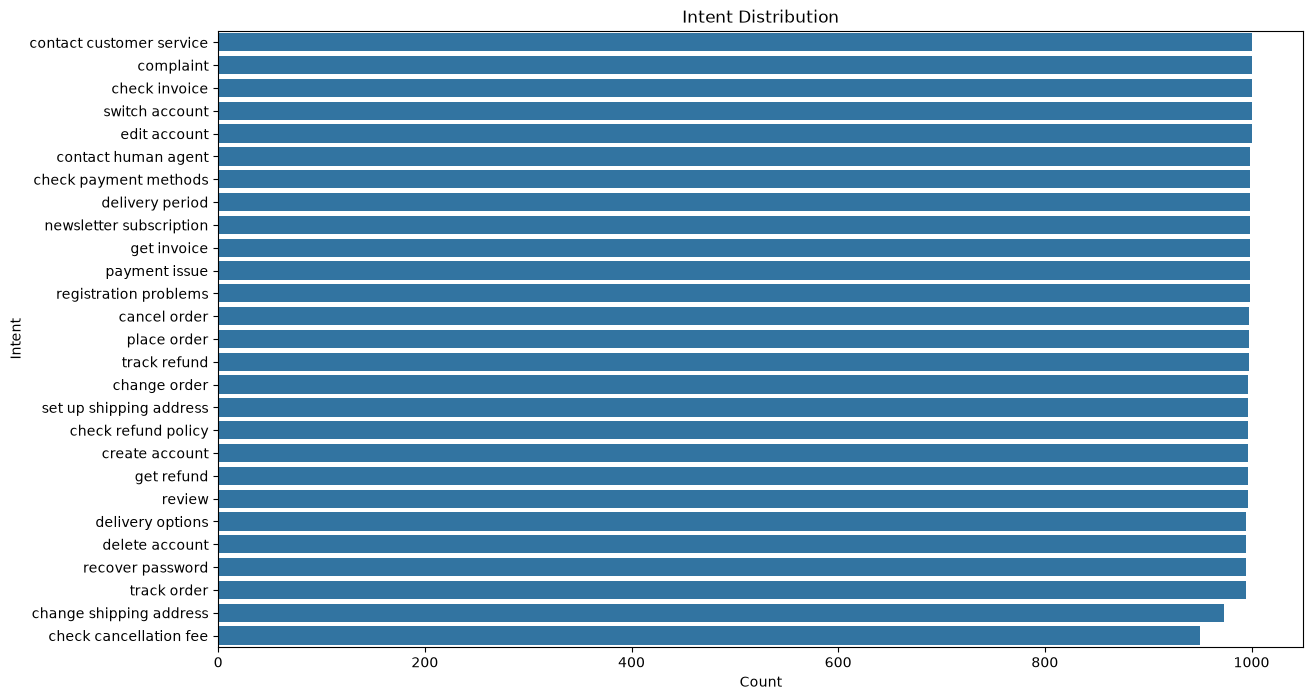

In [15]:
#EDA
#Intent Distribution
intent_counts = df['intent'].value_counts()

print(intent_counts)
plt.figure(figsize=(14, 8))
sns.countplot(data=df, y='intent',
              order=df['intent'].value_counts().index)
plt.title("Intent Distribution")
plt.xlabel("Count")
plt.ylabel("Intent")
plt.show()

Category Distribution:
category
account         5986
order           3988
refund          2992
contact         1999
invoice         1999
payment         1998
feedback        1997
delivery        1994
shipping        1970
subscription     999
cancel           950
Name: count, dtype: int64


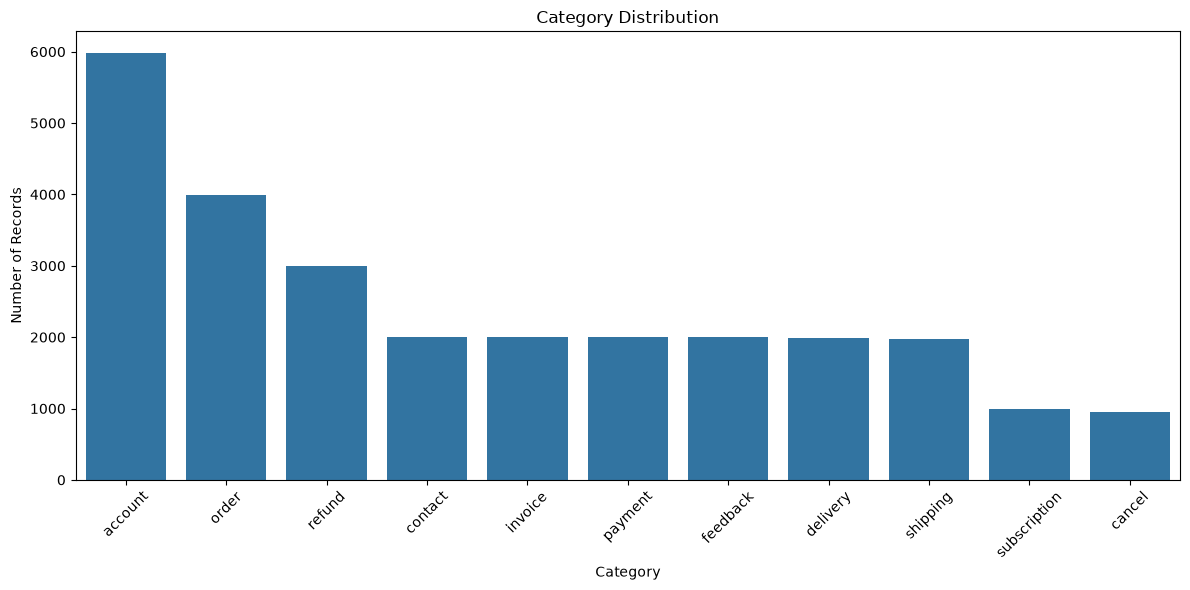

In [16]:
#Category Distribution
category_distribution = df['category'].value_counts()

print("Category Distribution:")
print(category_distribution)
plt.figure(figsize=(12, 6))

sns.barplot(
    x=category_distribution.index,
    y=category_distribution.values
)

plt.title("Category Distribution")
plt.xlabel("Category")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Instruction Length Statistics:
count    26872.000000
mean         8.763025
std          2.661975
min          1.000000
25%          7.000000
50%          9.000000
75%         11.000000
max         17.000000
Name: instruction_length, dtype: float64


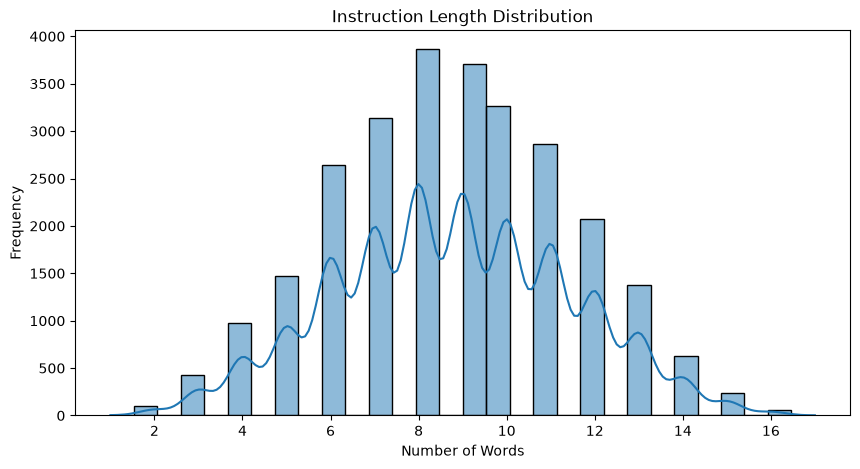

In [19]:
#Instruction Length Distribution
df['instruction_length'] = df['instruction'].apply(
    lambda x: len(str(x).split())
)

print("Instruction Length Statistics:")
print(df['instruction_length'].describe())
plt.figure(figsize=(10, 5))

sns.histplot(
    df['instruction_length'],
    bins=30,
    kde=True
)

plt.title("Instruction Length Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.show()

Response Length Statistics:
count    26872.000000
mean       107.497172
std         54.233131
min          9.000000
25%         74.000000
50%         92.000000
75%        128.000000
max        412.000000
Name: response_length, dtype: float64


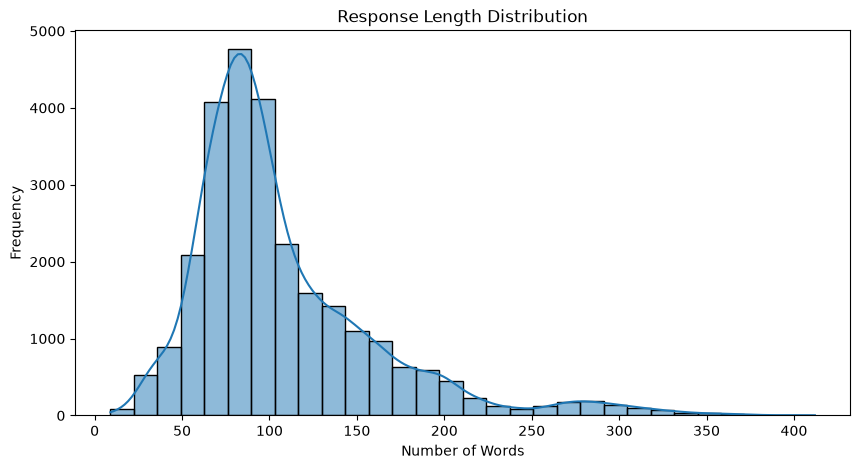

In [21]:
#Response Length Distribution
df['response_length'] = df['response'].apply(
    lambda x: len(str(x).split())
)

print("Response Length Statistics:")
print(df['response_length'].describe())
plt.figure(figsize=(10, 5))

sns.histplot(
    df['response_length'],
    bins=30,
    kde=True
)


plt.title("Response Length Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.show()

In [22]:
#Encode intent labels
label_encoder = LabelEncoder()

df['intent_label'] = label_encoder.fit_transform(df['intent'])

num_classes = len(label_encoder.classes_)

print("Total Intent Classes:", num_classes)

print("\nIntent Encoding:")

for i, intent in enumerate(label_encoder.classes_):
    print(i, ":", intent)

Total Intent Classes: 27

Intent Encoding:
0 : cancel order
1 : change order
2 : change shipping address
3 : check cancellation fee
4 : check invoice
5 : check payment methods
6 : check refund policy
7 : complaint
8 : contact customer service
9 : contact human agent
10 : create account
11 : delete account
12 : delivery options
13 : delivery period
14 : edit account
15 : get invoice
16 : get refund
17 : newsletter subscription
18 : payment issue
19 : place order
20 : recover password
21 : registration problems
22 : review
23 : set up shipping address
24 : switch account
25 : track order
26 : track refund


In [ ]:
#Train, Validation, Test Split

In [23]:
#Split dataset into training and testing
train_val, test_df = train_test_split(
    df,
    test_size=0.15,
    random_state=42,
    stratify=df['intent_label']
)

train_df, val_df = train_test_split(
    train_val,
    test_size=0.17647,
    random_state=42,
    stratify=train_val['intent_label']
)

print("Training Dataset:", train_df.shape)
print("Validation Dataset:", val_df.shape)
print("Testing Dataset:", test_df.shape)

Training Dataset: (18810, 10)
Validation Dataset: (4031, 10)
Testing Dataset: (4031, 10)


In [21]:
#Check splitting percentage
total_records = len(df)

print("Training:",
      round(len(train_df) / total_records * 100, 2), "%")

print("Validation:",
      round(len(val_df) / total_records * 100, 2), "%")


print("Testing:",
      round(len(test_df) / total_records * 100, 2), "%")

Training: 70.0 %
Validation: 15.0 %
Testing: 15.0 %


In [24]:
#Split dataset into training and testing
total_records = len(df)

print("Training:",
      round(len(train_df) / total_records * 100, 2), "%")

print("Validation:",
      round(len(val_df) / total_records * 100, 2), "%")

print("Testing:",
      round(len(test_df) / total_records * 100, 2), "%")

Training: 70.0 %
Validation: 15.0 %
Testing: 15.0 %


In [23]:
#Check splitting percentage
total_records = len(df)


print("Training:",
      round(len(train_df) / total_records * 100, 2), "%")

print("Validation:",
      round(len(val_df) / total_records * 100, 2), "%")

print("Testing:",
      round(len(test_df) / total_records * 100, 2), "%")

Training: 70.0 %
Validation: 15.0 %
Testing: 15.0 %


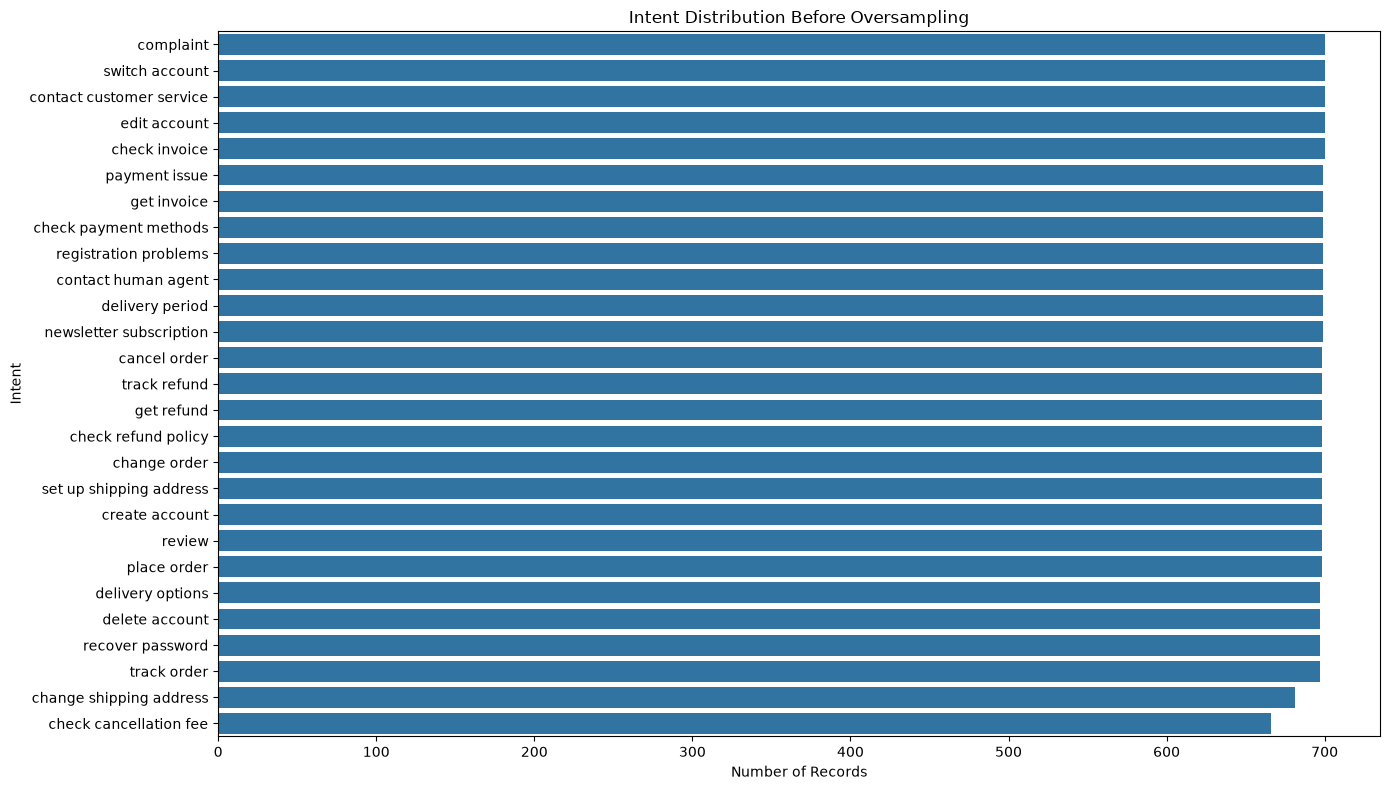

In [25]:
#Check class imbalance
plt.figure(figsize=(14, 8))

sns.countplot(
    data=train_df,
    y='intent',
    order=train_df['intent'].value_counts().index
)

plt.title("Intent Distribution Before Oversampling")
plt.xlabel("Number of Records")
plt.ylabel("Intent")

plt.tight_layout()
plt.show()

In [26]:
#Balance training dataset using oversampling
majority_count = train_df['intent'].value_counts().max()

balanced_data = []

for intent in train_df['intent'].unique():

    intent_data = train_df[
        train_df['intent'] == intent
    ]

    balanced_intent = resample(
        intent_data,
        replace=True,
        n_samples=majority_count,
        random_state=42
    )

    balanced_data.append(balanced_intent)

balanced_train = pd.concat(
    balanced_data
)

balanced_train = balanced_train.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print("Original Training Shape:", train_df.shape)

print("Balanced Training Shape:", balanced_train.shape)

Original Training Shape: (18810, 10)
Balanced Training Shape: (18900, 10)


In [27]:
#Check balanced dataset
print("Intent Distribution After Oversampling:")

print(balanced_train['intent'].value_counts())

Intent Distribution After Oversampling:
intent
track refund                700
change shipping address     700
track order                 700
place order                 700
get refund                  700
check invoice               700
edit account                700
switch account              700
check refund policy         700
delivery period             700
delivery options            700
check payment methods       700
delete account              700
change order                700
complaint                   700
contact human agent         700
cancel order                700
set up shipping address     700
get invoice                 700
newsletter subscription     700
payment issue               700
recover password            700
contact customer service    700
review                      700
create account              700
check cancellation fee      700
registration problems       700
Name: count, dtype: int64


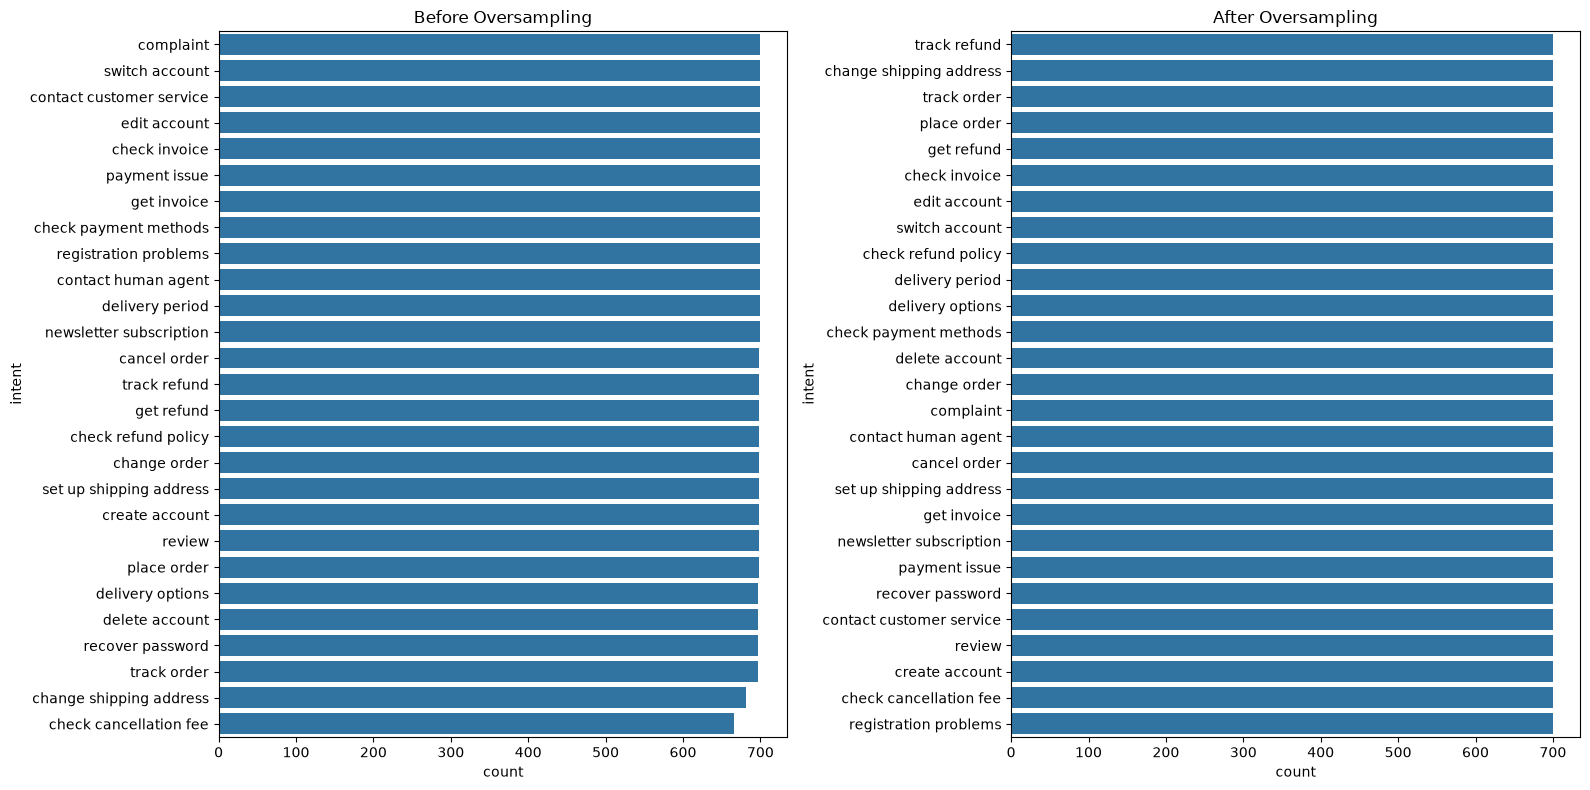

In [28]:
#Visualize before and after oversampling
plt.figure(figsize=(16, 8))

plt.subplot(1, 2, 1)

sns.countplot(
    data=train_df,
    y='intent',
    order=train_df['intent'].value_counts().index
)

plt.title("Before Oversampling")

plt.subplot(1, 2, 2)

sns.countplot(
    data=balanced_train,
    y='intent',
    order=balanced_train['intent'].value_counts().index
)

plt.title("After Oversampling")

plt.tight_layout()
plt.show()

In [29]:
#Tokenization
MAX_WORDS = 20000

tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(
    balanced_train['instruction']
)

vocab_size = min(
    len(tokenizer.word_index) + 1,
    MAX_WORDS
)

print("Vocabulary Size:", vocab_size)

Vocabulary Size: 1786


In [30]:
#Convert text into sequences
X_train_sequences = tokenizer.texts_to_sequences(
    balanced_train['instruction']
)

X_val_sequences = tokenizer.texts_to_sequences(
    val_df['instruction']
)

X_test_sequences = tokenizer.texts_to_sequences(
    test_df['instruction']
)

print("Training Sequence Example:")
print(X_train_sequences[0])

Training Sequence Example:
[2, 50, 189, 26, 7, 39, 14, 39, 75, 206]


In [31]:
#Padding
MAX_LEN = 50

X_train = pad_sequences(
    X_train_sequences,
    maxlen=MAX_LEN,
    padding='post',
    truncating='post'
)

X_val = pad_sequences(
    X_val_sequences,
    maxlen=MAX_LEN,
    padding='post',
    truncating='post'
)

X_test = pad_sequences(
    X_test_sequences,
    maxlen=MAX_LEN,
    padding='post',
    truncating='post'
)

print("Training Input Shape:", X_train.shape)
print("Validation Input Shape:", X_val.shape)
print("Testing Input Shape:", X_test.shape)

Training Input Shape: (18900, 50)
Validation Input Shape: (4031, 50)
Testing Input Shape: (4031, 50)


In [32]:
#Prepare target labels
y_train = balanced_train['intent_label'].values

y_val = val_df['intent_label'].values

y_test = test_df['intent_label'].values

print("Training Labels:", y_train.shape)
print("Validation Labels:", y_val.shape)
print("Testing Labels:", y_test.shape)

Training Labels: (18900,)
Validation Labels: (4031,)
Testing Labels: (4031,)


In [33]:
#Final dataset verification
print("FINAL DATASET SUMMARY")

print("Vocabulary Size:", vocab_size)

print("Maximum Sequence Length:", MAX_LEN)

print("Number of Intent Classes:", num_classes)

print("\nTraining Data:", X_train.shape)

print("Training Labels:", y_train.shape)

print("\nValidation Data:", X_val.shape)


print("Validation Labels:", y_val.shape)

print("\nTesting Data:", X_test.shape)

print("Testing Labels:", y_test.shape)

FINAL DATASET SUMMARY
Vocabulary Size: 1786
Maximum Sequence Length: 50
Number of Intent Classes: 27

Training Data: (18900, 50)
Training Labels: (18900,)

Validation Data: (4031, 50)
Validation Labels: (4031,)

Testing Data: (4031, 50)
Testing Labels: (4031,)


In [34]:
#import model libraries
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.optimizers import Adam

In [35]:
#Model 1 - Basic
model1 = Sequential()

model1.add(Embedding(
    input_dim=vocab_size,
    output_dim=128,
    input_length=MAX_LEN
))

model1.add(LSTM(64))

model1.add(Dense(64, activation='relu'))

model1.add(Dropout(0.3))

model1.add(Dense(num_classes, activation='softmax'))

model1.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding (Embedding)                │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm (LSTM)                          │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ ?                           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [36]:
#Train Model 1 
early_stop1 = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

checkpoint1 = ModelCheckpoint(
    'best_lstm_model1.keras',
    monitor='val_accuracy',
    save_best_only=True,
    mode='max'
)

history1 = model1.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=32,
    callbacks=[early_stop1, checkpoint1]
)

Epoch 1/10
591/591 ━━━━━━━━━━━━━━━━━━━━ 46s 65ms/step - accuracy: 0.0341 - loss: 3.2973 - val_accuracy: 0.0372 - val_loss: 3.2961
Epoch 2/10
591/591 ━━━━━━━━━━━━━━━━━━━━ 41s 64ms/step - accuracy: 0.0358 - loss: 3.2968 - val_accuracy: 0.0370 - val_loss: 3.2959
Epoch 3/10
591/591 ━━━━━━━━━━━━━━━━━━━━ 41s 65ms/step - accuracy: 0.0338 - loss: 3.2964 - val_accuracy: 0.0372 - val_loss: 3.2959
Epoch 4/10
591/591 ━━━━━━━━━━━━━━━━━━━━ 42s 66ms/step - accuracy: 0.0324 - loss: 3.2963 - val_accuracy: 0.0372 - val_loss: 3.2959
Epoch 5/10
591/591 ━━━━━━━━━━━━━━━━━━━━ 41s 65ms/step - accuracy: 0.0334 - loss: 3.2963 - val_accuracy: 0.0372 - val_loss: 3.2959
Epoch 6/10
591/591 ━━━━━━━━━━━━━━━━━━━━ 39s 66ms/step - accuracy: 0.0331 - loss: 3.2963 - val_accuracy: 0.0372 - val_loss: 3.2959
Epoch 7/10
591/591 ━━━━━━━━━━━━━━━━━━━━ 41s 65ms/step - accuracy: 0.0335 - loss: 3.2963 - val_accuracy: 0.0372 - val_loss: 3.2959
Epoch 8/10
591/591 ━━━━━━━━━━━━━━━━━━━━ 39s 61ms/step - accuracy: 0.0331 - loss: 3.2963 - 

In [37]:
#Model 1 Evaluation
loss1, accuracy1 = model1.evaluate(X_test, y_test)

print("Model 1 Test Loss:", loss1)
print("Model 1 Test Accuracy:", accuracy1)

126/126 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - accuracy: 0.0372 - loss: 3.2959
Model 1 Test Loss: 3.295858860015869
Model 1 Test Accuracy: 0.03721161186695099


In [39]:
#Model 2 – Stacked LSTM
model2 = Sequential()

model2.add(Embedding(
    input_dim=vocab_size,
    output_dim=128,
    input_length=MAX_LEN
))

model2.add(LSTM(128, return_sequences=True))

model2.add(Dropout(0.3))

model2.add(LSTM(64))

model2.add(Dense(64, activation='relu'))

model2.add(Dropout(0.3))

model2.add(Dense(num_classes, activation='softmax'))

model2.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model2.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)              │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_3 (LSTM)                        │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ ?                           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_4 (LSTM)                        │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ ?                           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [40]:
#Train Model 2 
early_stop2 = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

checkpoint2 = ModelCheckpoint(
    'best_lstm_model2.keras',
    monitor='val_accuracy',
    save_best_only=True,
    mode='max'
)

history2 = model2.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=32,
    callbacks=[early_stop2, checkpoint2]
)

Epoch 1/10
591/591 ━━━━━━━━━━━━━━━━━━━━ 33s 48ms/step - accuracy: 0.0365 - loss: 3.2973 - val_accuracy: 0.0372 - val_loss: 3.2959
Epoch 2/10
591/591 ━━━━━━━━━━━━━━━━━━━━ 31s 52ms/step - accuracy: 0.0335 - loss: 3.2965 - val_accuracy: 0.0370 - val_loss: 3.2960
Epoch 3/10
591/591 ━━━━━━━━━━━━━━━━━━━━ 29s 50ms/step - accuracy: 0.0501 - loss: 3.2267 - val_accuracy: 0.0707 - val_loss: 3.1355
Epoch 4/10
591/591 ━━━━━━━━━━━━━━━━━━━━ 40s 48ms/step - accuracy: 0.0664 - loss: 3.1381 - val_accuracy: 0.0705 - val_loss: 3.1105
Epoch 5/10
591/591 ━━━━━━━━━━━━━━━━━━━━ 29s 49ms/step - accuracy: 0.0668 - loss: 3.1183 - val_accuracy: 0.0702 - val_loss: 3.0988
Epoch 6/10
591/591 ━━━━━━━━━━━━━━━━━━━━ 30s 52ms/step - accuracy: 0.0721 - loss: 3.0980 - val_accuracy: 0.0707 - val_loss: 3.0660
Epoch 7/10
591/591 ━━━━━━━━━━━━━━━━━━━━ 41s 52ms/step - accuracy: 0.0661 - loss: 3.0822 - val_accuracy: 0.0705 - val_loss: 3.0701
Epoch 8/10
591/591 ━━━━━━━━━━━━━━━━━━━━ 33s 56ms/step - accuracy: 0.0672 - loss: 3.0722 - 

In [41]:
#Model 2 Evaluation
loss2, accuracy2 = model2.evaluate(X_test, y_test)

print("Model 2 Test Loss:", loss2)
print("Model 2 Test Accuracy:", accuracy2)

126/126 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - accuracy: 0.0690 - loss: 3.0652
Model 2 Test Loss: 3.065152645111084
Model 2 Test Accuracy: 0.06896551698446274


In [42]:
#Model 3 
model3 = Sequential()

model3.add(Embedding(
    input_dim=vocab_size,
    output_dim=128,
    input_length=MAX_LEN
))

model3.add(LSTM(128))

model3.add(Dropout(0.5))

model3.add(Dense(128, activation='relu'))

model3.add(Dropout(0.5))

model3.add(Dense(num_classes, activation='softmax'))

model3.compile(
    optimizer=Adam(learning_rate=0.0005),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model3.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)              │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_5 (LSTM)                        │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_5 (Dropout)                  │ ?                           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_6 (Dropout)                  │ ?                           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [43]:
#Train Model 3 
early_stop3 = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

checkpoint3 = ModelCheckpoint(
    'best_lstm_model3.keras',
    monitor='val_accuracy',
    save_best_only=True,
    mode='max'
)

history3 = model3.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=32,
    callbacks=[early_stop3, checkpoint3]
)

Epoch 1/10
591/591 ━━━━━━━━━━━━━━━━━━━━ 23s 33ms/step - accuracy: 0.0374 - loss: 3.2978 - val_accuracy: 0.0372 - val_loss: 3.2960
Epoch 2/10
591/591 ━━━━━━━━━━━━━━━━━━━━ 20s 34ms/step - accuracy: 0.0367 - loss: 3.2969 - val_accuracy: 0.0370 - val_loss: 3.2959
Epoch 3/10
591/591 ━━━━━━━━━━━━━━━━━━━━ 20s 33ms/step - accuracy: 0.0981 - loss: 2.9037 - val_accuracy: 0.3190 - val_loss: 1.8743
Epoch 4/10
591/591 ━━━━━━━━━━━━━━━━━━━━ 20s 34ms/step - accuracy: 0.3076 - loss: 1.7436 - val_accuracy: 0.4006 - val_loss: 1.3793
Epoch 5/10
591/591 ━━━━━━━━━━━━━━━━━━━━ 19s 32ms/step - accuracy: 0.4439 - loss: 1.2815 - val_accuracy: 0.5574 - val_loss: 1.0519
Epoch 6/10
591/591 ━━━━━━━━━━━━━━━━━━━━ 20s 34ms/step - accuracy: 0.5489 - loss: 0.9995 - val_accuracy: 0.6462 - val_loss: 0.8640
Epoch 7/10
591/591 ━━━━━━━━━━━━━━━━━━━━ 20s 34ms/step - accuracy: 0.6274 - loss: 0.8369 - val_accuracy: 0.7105 - val_loss: 0.8013
Epoch 8/10
591/591 ━━━━━━━━━━━━━━━━━━━━ 20s 33ms/step - accuracy: 0.6617 - loss: 0.8046 - 

In [44]:
#Model 3 Evaluation
loss3, accuracy3 = model3.evaluate(X_test, y_test)

print("Model 3 Test Loss:", loss3)
print("Model 3 Test Accuracy:", accuracy3)

126/126 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.8316 - loss: 0.5819
Model 3 Test Loss: 0.581874430179596
Model 3 Test Accuracy: 0.8315554261207581


In [45]:
#Compare All Three Models
model_comparison = pd.DataFrame({
    'Model': ['Basic LSTM', 'Stacked LSTM', 'LSTM with High Dropout'],
    'Test Accuracy': [accuracy1, accuracy2, accuracy3],
    'Test Loss': [loss1, loss2, loss3]
})

print(model_comparison)

                    Model  Test Accuracy  Test Loss
0              Basic LSTM       0.037212   3.295859
1            Stacked LSTM       0.068966   3.065153
2  LSTM with High Dropout       0.831555   0.581874


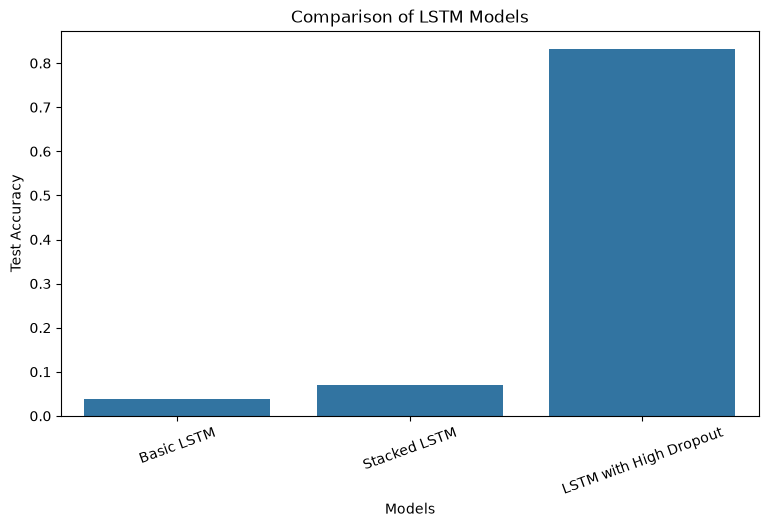

In [46]:
#Model Accuracy Visualization
plt.figure(figsize=(9, 5))

sns.barplot(
    data=model_comparison,
    x='Model',
    y='Test Accuracy'
)

plt.title("Comparison of LSTM Models")
plt.xlabel("Models")
plt.ylabel("Test Accuracy")
plt.xticks(rotation=20)
plt.show()

In [47]:
#Best Model
if accuracy1 >= accuracy2 and accuracy1 >= accuracy3:
    best_model = model1
    best_model_name = "Basic LSTM"

elif accuracy2 >= accuracy1 and accuracy2 >= accuracy3:
    best_model = model2
    best_model_name = "Stacked LSTM"

else:
    best_model = model3
    best_model_name = "High Dropout LSTM"

print("Best Model:", best_model_name)

Best Model: High Dropout LSTM


In [48]:
#Prediction
y_pred_prob = best_model.predict(X_test)

y_pred = np.argmax(y_pred_prob, axis=1)

126/126 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step


In [49]:
#Classification Report
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=label_encoder.classes_
))

                          precision    recall  f1-score   support

            cancel order       0.94      0.90      0.92       150
            change order       0.97      0.95      0.96       149
 change shipping address       0.98      0.92      0.95       146
  check cancellation fee       0.56      0.70      0.62       142
           check invoice       0.86      0.73      0.79       150
   check payment methods       0.87      0.89      0.88       150
     check refund policy       0.85      0.91      0.88       150
               complaint       0.71      0.93      0.80       150
contact customer service       0.88      0.91      0.90       150
     contact human agent       0.88      0.90      0.89       150
          create account       0.96      0.93      0.95       150
          delete account       0.91      0.91      0.91       149
        delivery options       0.38      0.19      0.26       149
         delivery period       0.97      0.97      0.97       150
         

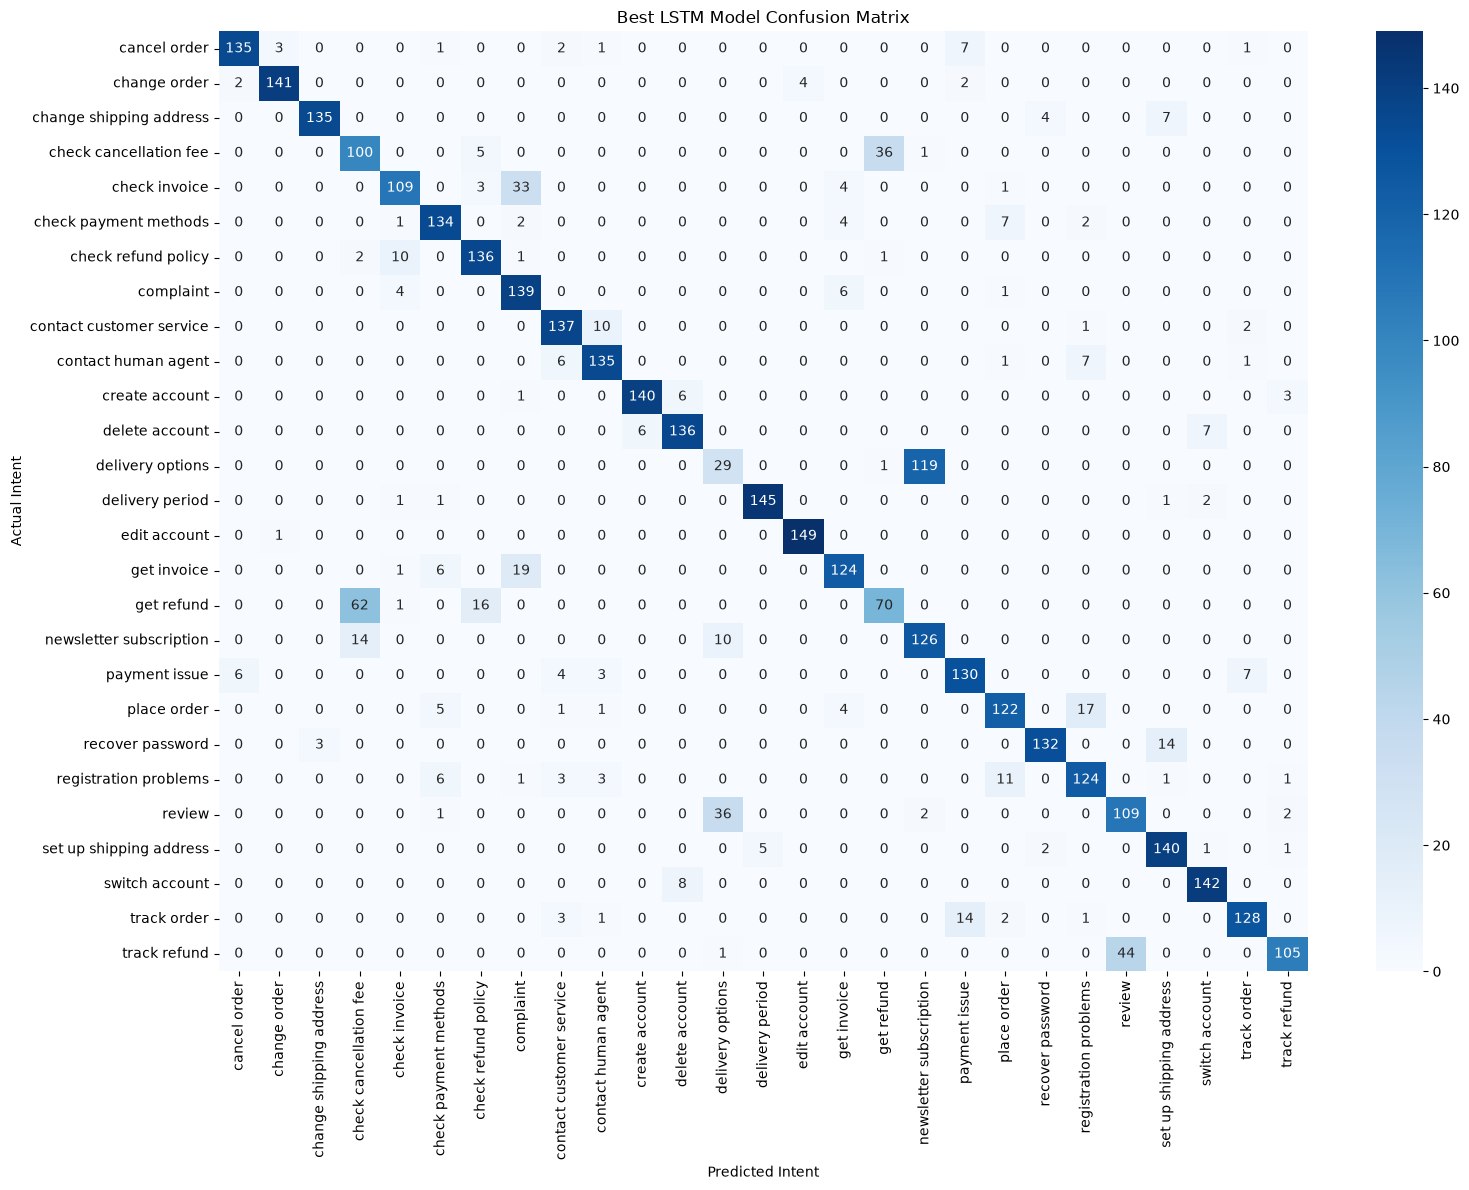

In [50]:
#Confusion Matrix
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(16, 12))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Best LSTM Model Confusion Matrix")
plt.xlabel("Predicted Intent")
plt.ylabel("Actual Intent")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [51]:
#Actual vs Predicted
results = pd.DataFrame({
    'Actual Intent': label_encoder.inverse_transform(y_test),
    'Predicted Intent': label_encoder.inverse_transform(y_pred)
})

print(results.head(20))

              Actual Intent         Predicted Intent
0            delete account           delete account
1            switch account           switch account
2              change order             change order
3              track refund             track refund
4             check invoice            check invoice
5     check payment methods    check payment methods
6              edit account             edit account
7                 complaint                complaint
8    check cancellation fee   check cancellation fee
9          delivery options         delivery options
10              get invoice                complaint
11                complaint                complaint
12   check cancellation fee   check cancellation fee
13      contact human agent      contact human agent
14            payment issue             cancel order
15             change order             change order
16             edit account             edit account
17  newsletter subscription  newsletter subscr

In [52]:
#DistilBERT Fine-Tuning
!pip install transformers torch accelerate

   ---------------------------------------- 0.0/13.5 MB ? eta -:--:--
   -------- ------------------------------- 2.9/13.5 MB 16.0 MB/s eta 0:00:01
   ------------- -------------------------- 4.7/13.5 MB 12.0 MB/s eta 0:00:01
   ----------------- ---------------------- 5.8/13.5 MB 9.9 MB/s eta 0:00:01
   -------------------- ------------------- 6.8/13.5 MB 8.3 MB/s eta 0:00:01
   -------------------- ------------------- 7.1/13.5 MB 7.6 MB/s eta 0:00:01
   ---------------------- ----------------- 7.6/13.5 MB 6.0 MB/s eta 0:00:01
   ----------------------- ---------------- 8.1/13.5 MB 5.4 MB/s eta 0:00:02
   ------------------------- -------------- 8.7/13.5 MB 5.0 MB/s eta 0:00:01
   --------------------------- ------------ 9.2/13.5 MB 4.8 MB/s eta 0:00:01
   ---------------------------- ----------- 9.7/13.5 MB 4.7 MB/s eta 0:00:01
   ------------------------------ --------- 10.5/13.5 MB 4.5 MB/s eta 0:00:01
   --------------------------------- ------ 11.3/13.5 MB 4.5 MB/s eta 0:00:01
  

In [53]:
import torch
import time

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer
)

from sklearn.metrics import accuracy_score, precision_recall_fscore_support

In [54]:
#Load DistilBERT
MODEL_NAME = "distilbert-base-uncased"

bert_tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

distilbert_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=num_classes
)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [56]:
#Prepare Dataset
train_texts = balanced_train['instruction'].tolist()
val_texts = val_df['instruction'].tolist()
test_texts = test_df['instruction'].tolist()

train_labels = balanced_train['intent_label'].tolist()
val_labels = val_df['intent_label'].tolist()
test_labels = test_df['intent_label'].tolist()

In [57]:
#Tokenization
train_encodings = bert_tokenizer(
    train_texts,
    truncation=True,
    padding=True,
    max_length=128
)

val_encodings = bert_tokenizer(
    val_texts,
    truncation=True,
    padding=True,
    max_length=128
)

test_encodings = bert_tokenizer(
    test_texts,
    truncation=True,
    padding=True,
    max_length=128
)

In [59]:
#Create PyTorch Dataset
class CustomerDataset(torch.utils.data.Dataset):

    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __getitem__(self, idx):
        item = {
            key: torch.tensor(val[idx])
            for key, val in self.encodings.items()
        }

        item['labels'] = torch.tensor(self.labels[idx])
        return item

    def __len__(self):
        return len(self.labels)


train_dataset = CustomerDataset(train_encodings, train_labels)
val_dataset = CustomerDataset(val_encodings, val_labels)
test_dataset = CustomerDataset(test_encodings, test_labels)

In [61]:
#Define Metrics
def compute_metrics(pred):

    labels = pred.label_ids
    predictions = np.argmax(pred.predictions, axis=1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average='weighted',
        zero_division=0
    )

    accuracy = accuracy_score(labels, predictions)

    return {
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1': f1
    }

In [63]:
#Training Arguments
training_args = TrainingArguments(
    output_dir='./distilbert_results',
    num_train_epochs=3,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    eval_strategy='epoch',
    save_strategy='epoch',
    load_best_model_at_end=True,
    metric_for_best_model='accuracy',
    report_to='none'
)

In [64]:
#Train DistilBERT
trainer = Trainer(
    model=distilbert_model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics
)

start_time = time.time()

trainer.train()

distilbert_training_time = time.time() - start_time

print("DistilBERT Training Time:", distilbert_training_time)

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.015881,0.019027,0.997271,0.997294,0.997271,0.997273
2,0.000534,0.023053,0.997023,0.997057,0.997023,0.997025
3,0.000216,0.019642,0.997519,0.997537,0.997519,0.997520


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

DistilBERT Training Time: 5247.554339170456


In [65]:
#Evaluate DistilBERT
distilbert_results = trainer.evaluate(test_dataset)

print("DistilBERT Test Results:")
print(distilbert_results)

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.000216,0.020889,3,0.996279,0.996294,0.996279,0.996275


DistilBERT Test Results:
{'eval_loss': 0.020888861268758774, 'eval_accuracy': 0.9962788389977673, 'eval_precision': 0.9962936811753585, 'eval_recall': 0.9962788389977673, 'eval_f1': 0.9962745782108297}


In [66]:
#Save DistilBERT
trainer.save_model("./best_distilbert_model")

bert_tokenizer.save_pretrained("./best_distilbert_model")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('./best_distilbert_model\\tokenizer_config.json',
 './best_distilbert_model\\tokenizer.json')

In [67]:
#BERT Base Fine-Tuning
BERT_NAME = "bert-base-uncased"

bert_base_tokenizer = AutoTokenizer.from_pretrained(BERT_NAME)

bert_base_model = AutoModelForSequenceClassification.from_pretrained(
    BERT_NAME,
    num_labels=num_classes
)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [69]:
#Tokenization
bert_train_encodings = bert_base_tokenizer(
    train_texts,
    truncation=True,
    padding=True,
    max_length=128
)

bert_val_encodings = bert_base_tokenizer(
    val_texts,
    truncation=True,
    padding=True,
    max_length=128
)

bert_test_encodings = bert_base_tokenizer(
    test_texts,
    truncation=True,
    padding=True,
    max_length=128
)

In [71]:
#Dataset
bert_train_dataset = CustomerDataset(
    bert_train_encodings, train_labels
)

bert_val_dataset = CustomerDataset(
    bert_val_encodings, val_labels
)

bert_test_dataset = CustomerDataset(
    bert_test_encodings, test_labels
)

In [72]:
#Training Arguments
bert_training_args = TrainingArguments(
    output_dir='./bert_results',
    num_train_epochs=3,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    eval_strategy='epoch',
    save_strategy='epoch',
    load_best_model_at_end=True,
    metric_for_best_model='accuracy',
    report_to='none'
)

In [73]:
#Train BERT
bert_trainer = Trainer(
    model=bert_base_model,
    args=bert_training_args,
    train_dataset=bert_train_dataset,
    eval_dataset=bert_val_dataset,
    compute_metrics=compute_metrics
)

start_time = time.time()

bert_trainer.train()

bert_training_time = time.time() - start_time

print("BERT Training Time:", bert_training_time)

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.017578,0.034620,0.994046,0.994193,0.994046,0.994052
2,0.003090,0.024805,0.996527,0.996579,0.996527,0.996529
3,0.000141,0.022514,0.997271,0.997304,0.997271,0.997272


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

BERT Training Time: 20914.724036216736


In [76]:
#Evaluate BERT
bert_results = bert_trainer.evaluate(bert_test_dataset)

print("BERT Test Results:")
print(bert_results)

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.000141,0.021453,3,0.996775,0.996798,0.996775,0.996777


BERT Test Results:
{'eval_loss': 0.02145273983478546, 'eval_accuracy': 0.996774993798065, 'eval_precision': 0.9967979958222697, 'eval_recall': 0.996774993798065, 'eval_f1': 0.9967774069880273}


In [75]:
#Save BERT
bert_trainer.save_model("./best_bert_model")

bert_base_tokenizer.save_pretrained("./best_bert_model")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('./best_bert_model\\tokenizer_config.json',
 './best_bert_model\\tokenizer.json')

In [77]:
#Get LSTM Evaluation Metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

lstm_accuracy = accuracy_score(y_test, y_pred)

lstm_precision = precision_score(
    y_test, y_pred, average='weighted', zero_division=0
)

lstm_recall = recall_score(
    y_test, y_pred, average='weighted', zero_division=0
)

lstm_f1 = f1_score(
    y_test, y_pred, average='weighted', zero_division=0
)

In [79]:
#Get DistilBERT Predictions
distilbert_predictions = trainer.predict(test_dataset)

distilbert_y_pred = np.argmax(
    distilbert_predictions.predictions, axis=1
)

distilbert_y_true = distilbert_predictions.label_ids

In [80]:
#Get BERT Predictions
bert_predictions = bert_trainer.predict(bert_test_dataset)

bert_y_pred = np.argmax(
    bert_predictions.predictions, axis=1
)

bert_y_true = bert_predictions.label_ids

In [81]:
#Calculate Transformer Metrics
distilbert_accuracy = accuracy_score(
    distilbert_y_true, distilbert_y_pred
)

distilbert_precision = precision_score(
    distilbert_y_true, distilbert_y_pred,
    average='weighted', zero_division=0
)

distilbert_recall = recall_score(
    distilbert_y_true, distilbert_y_pred,
    average='weighted', zero_division=0
)

distilbert_f1 = f1_score(
    distilbert_y_true, distilbert_y_pred,
    average='weighted', zero_division=0
)


bert_accuracy = accuracy_score(
    bert_y_true, bert_y_pred
)

bert_precision = precision_score(
    bert_y_true, bert_y_pred,
    average='weighted', zero_division=0
)

bert_recall = recall_score(
    bert_y_true, bert_y_pred,
    average='weighted', zero_division=0
)

bert_f1 = f1_score(
    bert_y_true, bert_y_pred,
    average='weighted', zero_division=0
)

In [82]:
#Create Final Comparison Table
final_comparison = pd.DataFrame({
    'Model': ['Custom LSTM', 'DistilBERT', 'BERT Base'],

    'Accuracy': [
        lstm_accuracy,
        distilbert_accuracy,
        bert_accuracy
    ],

    'Precision': [
        lstm_precision,
        distilbert_precision,
        bert_precision
    ],

    'Recall': [
        lstm_recall,
        distilbert_recall,
        bert_recall
    ],

    'F1 Score': [
        lstm_f1,
        distilbert_f1,
        bert_f1
    ]
})

print(final_comparison)

         Model  Accuracy  Precision    Recall  F1 Score
0  Custom LSTM  0.831555   0.835387  0.831555  0.828319
1   DistilBERT  0.996279   0.996294  0.996279  0.996275
2    BERT Base  0.996775   0.996798  0.996775  0.996777


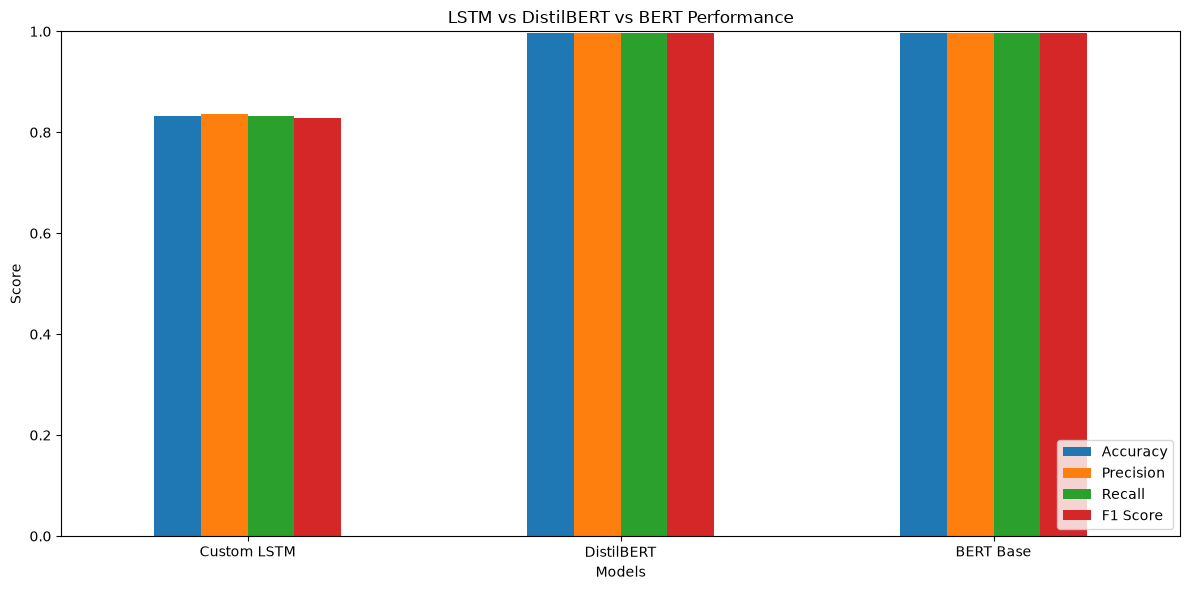

In [83]:
final_comparison.set_index('Model').plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title("LSTM vs DistilBERT vs BERT Performance")
plt.ylabel("Score")
plt.xlabel("Models")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [84]:
#Seq2Seq Query Extraction
import random

greetings = [
    "hello",
    "hi support team",
    "dear customer service",
    "good morning"
]

signatures = [
    "thank you",
    "regards",
    "best regards",
    "thanks for your help"
]

def create_noisy_text(text):
    greeting = random.choice(greetings)
    signature = random.choice(signatures)

    return greeting + " " + text + " " + signature

df['noisy_instruction'] = df['instruction'].apply(create_noisy_text)

df[['noisy_instruction', 'instruction']].head()

,noisy_instruction,instruction
0,good morning Question about cancelling order o...,Question about cancelling order order number
1,hello I have a question about cancelling oorde...,I have a question about cancelling oorder orde...
2,hi support team I need help cancelling puchase...,I need help cancelling puchase order number
3,hello I need to cancel purchase order number r...,I need to cancel purchase order number
4,good morning I cannot afford this order cancel...,I cannot afford this order cancel purchase ord...


In [85]:
#Tokenization
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

seq_tokenizer = Tokenizer(
    num_words=20000,
    oov_token="<OOV>"
)

seq_tokenizer.fit_on_texts(
    df['noisy_instruction'].tolist() + df['instruction'].tolist()
)

seq_vocab_size = min(len(seq_tokenizer.word_index) + 1, 20000)

print("Vocabulary Size:", seq_vocab_size)

Vocabulary Size: 2883


In [86]:
#Convert Text into Sequences
encoder_sequences = seq_tokenizer.texts_to_sequences(
    df['noisy_instruction']
)

decoder_sequences = seq_tokenizer.texts_to_sequences(
    df['instruction']
)

SEQ_MAX_LEN = 60

encoder_input = pad_sequences(
    encoder_sequences,
    maxlen=SEQ_MAX_LEN,
    padding='post',
    truncating='post'
)

decoder_target = pad_sequences(
    decoder_sequences,
    maxlen=SEQ_MAX_LEN,
    padding='post',
    truncating='post'
)

print("Encoder Input:", encoder_input.shape)
print("Decoder Target:", decoder_target.shape)

Encoder Input: (26872, 60)
Decoder Target: (26872, 60)


In [87]:
#Train-Test Split
from sklearn.model_selection import train_test_split

enc_train, enc_val, dec_train, dec_val = train_test_split(
    encoder_input,
    decoder_target,
    test_size=0.15,
    random_state=42
)

print("Training:", enc_train.shape)
print("Validation:", enc_val.shape)

Training: (22841, 60)
Validation: (4031, 60)


In [88]:
#Prepare Decoder Input and Output
decoder_input_train = dec_train[:, :-1]
decoder_output_train = dec_train[:, 1:]

decoder_input_val = dec_val[:, :-1]
decoder_output_val = dec_val[:, 1:]

print("Decoder Input:", decoder_input_train.shape)
print("Decoder Output:", decoder_output_train.shape)

Decoder Input: (22841, 59)
Decoder Output: (22841, 59)


In [89]:
#Create Encoder-Decoder LSTM Model
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense

# Encoder
encoder_inputs = Input(shape=(SEQ_MAX_LEN,))
encoder_embedding = Embedding(
    seq_vocab_size, 128, mask_zero=True
)(encoder_inputs)

encoder_lstm = LSTM(128, return_state=True)

_, state_h, state_c = encoder_lstm(encoder_embedding)

encoder_states = [state_h, state_c]

# Decoder
decoder_inputs = Input(shape=(SEQ_MAX_LEN - 1,))

decoder_embedding_layer = Embedding(
    seq_vocab_size, 128, mask_zero=True
)

decoder_embedding = decoder_embedding_layer(decoder_inputs)

decoder_lstm = LSTM(128, return_sequences=True, return_state=True)

decoder_outputs, _, _ = decoder_lstm(
    decoder_embedding,
    initial_state=encoder_states
)

decoder_dense = Dense(seq_vocab_size, activation='softmax')

decoder_outputs = decoder_dense(decoder_outputs)

seq2seq_model = Model(
    [encoder_inputs, decoder_inputs],
    decoder_outputs
)

seq2seq_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

seq2seq_model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)    │ (None, 60)                │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ input_layer_4 (InputLayer)    │ (None, 59)                │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ embedding_4 (Embedding)       │ (None, 60, 128)           │         369,024 │ input_layer_3[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ not_equal (NotEqual)          │ (None, 60)                │               0 │ input_layer_3[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ embedding_5 (Embedding)       │ (None, 59, 128)           │         369,024 │ input_layer_4[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ lstm_6 (LSTM)                 │ [(None, 128), (None,      │         131,584 │ embedding_4[0][0],         │
│                               │ 128), (None, 128)]        │                 │ not_equal[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ lstm_7 (LSTM)                 │ [(None, 59, 128), (None,  │         131,584 │ embedding_5[0][0],         │
│                               │ 128), (None, 128)]        │                 │ lstm_6[0][1], lstm_6[0][2] │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_8 (Dense)               │ (None, 59, 2883)          │         371,907 │ lstm_7[0][0]               │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 1,373,123 (5.24 MB)

 Trainable params: 1,373,123 (5.24 MB)

 Non-trainable params: 0 (0.00 B)

In [90]:
#Train Seq2Seq Model
from tensorflow.keras.callbacks import EarlyStopping

seq_early_stop = EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True
)

seq_history = seq2seq_model.fit(
    [enc_train, decoder_input_train],
    decoder_output_train,
    validation_data=(
        [enc_val, decoder_input_val],
        decoder_output_val
    ),
    epochs=5,
    batch_size=32,
    callbacks=[seq_early_stop],
    verbose=1
)

Epoch 1/5
714/714 ━━━━━━━━━━━━━━━━━━━━ 281s 376ms/step - accuracy: 0.3037 - loss: 3.6671 - val_accuracy: 0.4966 - val_loss: 2.4458
Epoch 2/5
714/714 ━━━━━━━━━━━━━━━━━━━━ 172s 166ms/step - accuracy: 0.6034 - loss: 1.8443 - val_accuracy: 0.6814 - val_loss: 1.4456
Epoch 3/5
714/714 ━━━━━━━━━━━━━━━━━━━━ 117s 164ms/step - accuracy: 0.7435 - loss: 1.1457 - val_accuracy: 0.7831 - val_loss: 0.9994
Epoch 4/5
714/714 ━━━━━━━━━━━━━━━━━━━━ 118s 165ms/step - accuracy: 0.8229 - loss: 0.7978 - val_accuracy: 0.8397 - val_loss: 0.7595
Epoch 5/5
714/714 ━━━━━━━━━━━━━━━━━━━━ 123s 172ms/step - accuracy: 0.8761 - loss: 0.5831 - val_accuracy: 0.8870 - val_loss: 0.6018


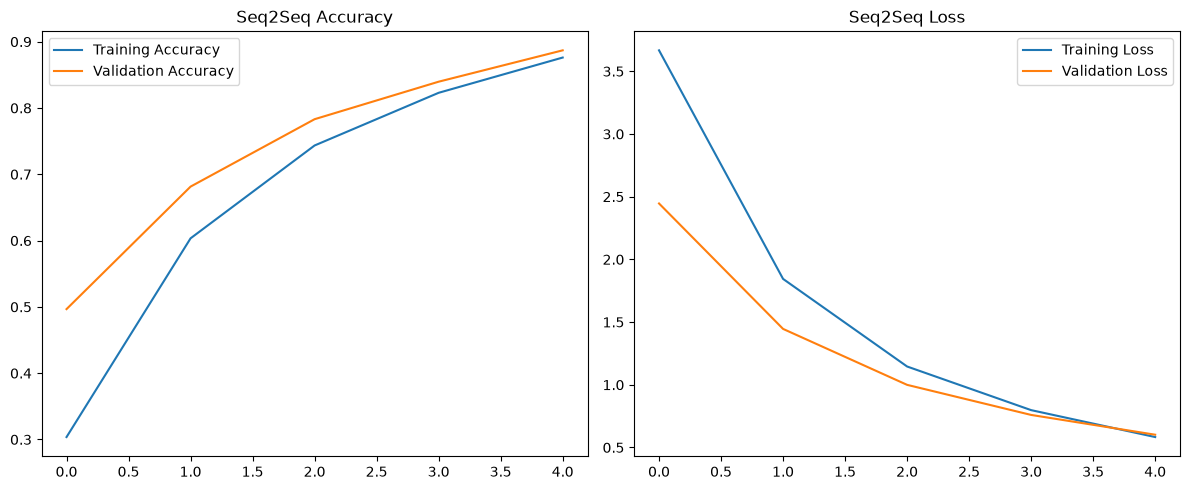

In [91]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(seq_history.history['accuracy'], label='Training Accuracy')
plt.plot(seq_history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Seq2Seq Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(seq_history.history['loss'], label='Training Loss')
plt.plot(seq_history.history['val_loss'], label='Validation Loss')
plt.title('Seq2Seq Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [92]:
#Save Seq2Seq Model
seq2seq_model.save("best_seq2seq_model.keras")

seq_tokenizer_path = "seq2seq_tokenizer.json"

import json

with open(seq_tokenizer_path, "w") as file:
    file.write(seq_tokenizer.to_json())

In [93]:
#Seq2Seq Query Extraction Prediction
# Encoder Model
encoder_model = Model(
    encoder_inputs,
    encoder_states
)

# Decoder States
decoder_state_input_h = Input(shape=(128,))
decoder_state_input_c = Input(shape=(128,))

decoder_state_inputs = [
    decoder_state_input_h,
    decoder_state_input_c
]

decoder_embedding_inf = decoder_embedding_layer(decoder_inputs)

decoder_outputs_inf, state_h_inf, state_c_inf = decoder_lstm(
    decoder_embedding_inf,
    initial_state=decoder_state_inputs
)

decoder_outputs_inf = decoder_dense(decoder_outputs_inf)

decoder_model = Model(
    [decoder_inputs] + decoder_state_inputs,
    [decoder_outputs_inf, state_h_inf, state_c_inf]
)

In [96]:
#Query Extraction Function
def extract_query(text):

    text = clean_text(text)

    sequence = seq_tokenizer.texts_to_sequences([text])

    padded = pad_sequences(
        sequence,
        maxlen=SEQ_MAX_LEN,
        padding='post',
        truncating='post'
    )

    states = encoder_model.predict(padded, verbose=0)

    decoder_input = np.zeros((1, SEQ_MAX_LEN - 1), dtype='int32')

    # Use the input sequence as the decoder prompt
    decoder_input[0, 0] = sequence[0][0] if sequence[0] else 0

    prediction, _, _ = decoder_model.predict(
        [decoder_input] + states,
        verbose=0
    )

    predicted_ids = np.argmax(prediction[0], axis=-1)

    words = []

    for word_id in predicted_ids:
        if word_id == 0:
            break

        word = seq_tokenizer.index_word.get(word_id, '')

        if word:
            words.append(word)

    return " ".join(words)

In [97]:
#Test Query Extraction
sample_text = "hello support team i need help with my payment thank you"

extracted_query = extract_query(sample_text)

print("Original Ticket:", sample_text)
print("Extracted Query:", extracted_query)

Original Ticket: hello support team i need help with my payment thank you
Extracted Query: with with of of help


In [98]:
#Intent Classification + Automatic Response
def predict_intent(text):

    text = clean_text(text)

    sequence = tokenizer.texts_to_sequences([text])

    padded = pad_sequences(
        sequence,
        maxlen=MAX_LEN,
        padding='post',
        truncating='post'
    )

    probabilities = best_model.predict(padded, verbose=0)[0]

    predicted_label = np.argmax(probabilities)

    predicted_intent = label_encoder.inverse_transform(
        [predicted_label]
    )[0]

    confidence = float(probabilities[predicted_label])

    return predicted_intent, confidence

In [99]:
#Automatic Response Function
def get_response(predicted_intent):

    matching_responses = df[
        df['intent'] == predicted_intent
    ]['response']

    if len(matching_responses) > 0:
        return matching_responses.iloc[0]

    return "Sorry, no matching response found."

In [100]:
#Connect Both Models
def customer_support_system(ticket):

    extracted_query = extract_query(ticket)

    predicted_intent, confidence = predict_intent(
        extracted_query
    )

    response = get_response(predicted_intent)

    print("Original Ticket:", ticket)
    print("Extracted Query:", extracted_query)
    print("Predicted Intent:", predicted_intent)
    print("Confidence:", round(confidence * 100, 2), "%")
    print("Automatic Response:", response)

In [101]:
#Test Complete System
customer_support_system(
    "Hello team, I am facing an issue with my payment. Please help me. Thank you."
)

Original Ticket: Hello team, I am facing an issue with my payment. Please help me. Thank you.
Extracted Query: an an an an my my my my my
Predicted Intent: create account
Confidence: 49.0 %
Automatic Response: It is fantastic to hear that you would like to create a new account type account for your wife i am here to assist you in every step of the process to get started could you please provide me with your wife s full name email address and a username of her preference this will allow us to set up the account accurately and ensure her privacy and security once we have these details we can proceed with creating her account type account and unlocking all its benefits if you have any questions or need further assistance please do not hesitate to let me know how are you feeling about this exciting opportunity for your wife to join us as a account type member


In [103]:
#Save Models
best_model.save("best_intent_lstm.keras")

seq2seq_model.save("best_seq2seq_model.keras")

print("Models Saved Successfully!")

Models Saved Successfully!


In [104]:
import pickle
import os

folder = r"C:\Users\mchar\Final Project"

with open(os.path.join(folder, "tokenizer.pkl"), "wb") as f:
    pickle.dump(tokenizer, f)

with open(os.path.join(folder, "label_encoder.pkl"), "wb") as f:
    pickle.dump(label_encoder, f)

df.to_csv(
    os.path.join(folder, "customer_support_data.csv"),
    index=False
)

print("All files saved successfully!")

All files saved successfully!


In [105]:
import os

folder = r"C:\Users\mchar\Final Project"

os.makedirs(folder, exist_ok=True)

best_model.save(os.path.join(folder, "best_model.keras"))

print("Model saved successfully!")

Model saved successfully!
